Exercise 1 - Trapping electrons in a semiconductor

Impurities can have a major role in determining the physical properties of semiconductors, especially in terms of electrical conductivity. For instance, a localized impurity can act as a \"trap for electrons\", bounding them to a specific region of the semiconductor. The following wave function, obtained by solving the stationary Schrodinger equation, describes the quantum state of an electron trapped nearby an impurity in an idealized 1-dimensional semiconductor
$$\psi(x) := e^{-|x|} \quad x \in \Omega$$
Here, the impurity is located at $x_0 = 0$, whereas $\Omega = (-\infty,+\infty)$ represents the semiconductor (which, compared to the size of the electron, can be though as being \"infinitely long\").

Let $\hat{\psi} = \hat{\psi}(s)$ be the Fourier transform of $\psi$. A direct computation shows that
$$\hat{\psi}(s) = \sqrt{\frac{2}{\pi}} \frac{1}{1 + s^2}$$
In quantum mechanics, $\psi$ and $\hat{\psi}$ correspond to the wave function of the electron with respect to its position and momentum, respectively. In particular, according to Born's rule, if one were to measure the momentum of the particle, the result $S$ would be a random variable with probability density function given by
$$f(s) = |\hat{\psi}(s)|^2 = \frac{2}{\pi(1 + s^2)^2}.$$

max |F'(s) - f(s)| = 4.2441278058635845e-07
mean |F'(s) - f(s)| = 2.1967695971699138e-08


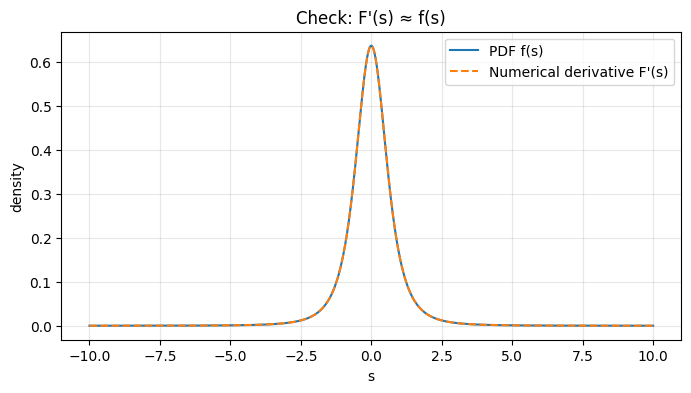

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def pdf(s):
    return 2.0 / (np.pi * (1.0 + s**2)**2)

def cdf(s):
    return 0.5 + (1.0/np.pi)*np.arctan(s) + s/(np.pi*(1.0 + s**2))

# 1) grid
s = np.linspace(-10, 10, 20001)
ds = s[1] - s[0]

# 2) evaluate
f = pdf(s)
F = cdf(s)

# 3) numerical derivative of CDF
dF = np.gradient(F, ds)

# 4) error metrics
abs_err = np.abs(dF - f)
print("max |F'(s) - f(s)| =", abs_err.max())
print("mean |F'(s) - f(s)| =", abs_err.mean())

# 5) plot (presentation-friendly)
plt.figure(figsize=(8,4))
plt.plot(s, f, label="PDF f(s)")
plt.plot(s, dF, "--", label="Numerical derivative F'(s)")
plt.title("Check: F'(s) ≈ f(s)")
plt.xlabel("s")
plt.ylabel("density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
# Define true PDF and true CDF (given in the assignment)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import cauchy, kstest

def pdf_true(s):
    return 2.0 / (np.pi * (1.0 + s**2)**2)

def cdf_true(s):
    # CDF given in the assignment
    return 0.5 + (1.0/np.pi)*np.arctan(s) + s/(np.pi*(1.0 + s**2))


## Exercise 1(b) — Sampling and validation

We are given a random variable $S$ with probability density function:

$$
f_S(s)=\frac{2}{\pi(1+s^2)^2},\qquad s\in\mathbb{R}.
$$

The corresponding cumulative distribution function is:

$$
F_S(s)=\frac{1}{2}+\frac{1}{\pi}\arctan(s)+\frac{s}{\pi(1+s^2)}.
$$

### Sampling idea (Acceptance–Rejection with Cauchy proposal)

The inverse CDF $F_S^{-1}$ is not available in closed form, so we use **acceptance–rejection**.

Choose as proposal the standard Cauchy distribution:

$$
g(s)=\frac{1}{\pi(1+s^2)}.
$$

We can bound the target density by the proposal:

$$
f_S(s)=\frac{2}{\pi(1+s^2)^2}\le \frac{2}{\pi(1+s^2)} = 2g(s)\quad \forall s.
$$

So we can take the rejection constant $C=2$.  
The acceptance probability becomes:

$$
\alpha(s)=\frac{f_S(s)}{C\,g(s)}=\frac{1}{1+s^2}.
$$

### Algorithm (AR)

Repeat until we have $N=1000$ accepted samples:

1. Draw $Y \sim \text{Cauchy}(0,1)$  
2. Draw $U \sim \text{Unif}(0,1)$  
3. Accept $Y$ as a sample of $S$ if:

$$
U \le \alpha(Y)=\frac{1}{1+Y^2}.
$$

### Comparison with the true distribution

We compare the generated samples to the true distribution by:

- plotting the **normalized histogram** of samples and overlaying the true PDF $f_S$
- plotting the **empirical CDF** and overlaying the true CDF $F_S$

### Quantitative validation (Kolmogorov–Smirnov test)

We perform a Kolmogorov–Smirnov test using the theoretical CDF $F_S$:

$$
D=\sup_s \left|F_N(s)-F_S(s)\right|,
$$

where $F_N$ is the empirical CDF of the $N=1000$ samples.


Acceptance–Rejection sampler using Cauchy proposal

In [ ]:
import numpy as np

def sample_S_ar(N, seed=0):

    rng = np.random.default_rng(seed)

    S = []
    trials = 0

    while len(S) < N:

        # 1) sample from proposal g (Cauchy)
        y = np.tan(np.pi * (rng.random() - 0.5))   # inverse CDF of Cauchy

        # 2) sample uniform
        u = rng.random()

        trials += 1

        # 3) acceptance test
        if u <= 1.0 / (1.0 + y**2):
            S.append(y)

    S = np.array(S)

    acc_rate = N / trials

    return S, acc_rate


# ---- Run ----
N = 1000
S, acc_rate = sample_S_ar(N, seed=42)

print("Acceptance rate:", acc_rate)
print("Sample mean:", S.mean())
print("Sample std:", S.std(ddof=1))


Acceptance rate: 0.49382716049382713
Sample mean: -0.02241890337653777
Sample std: 0.9724161708618269


3) Qualitative comparison: histogram vs true PDF

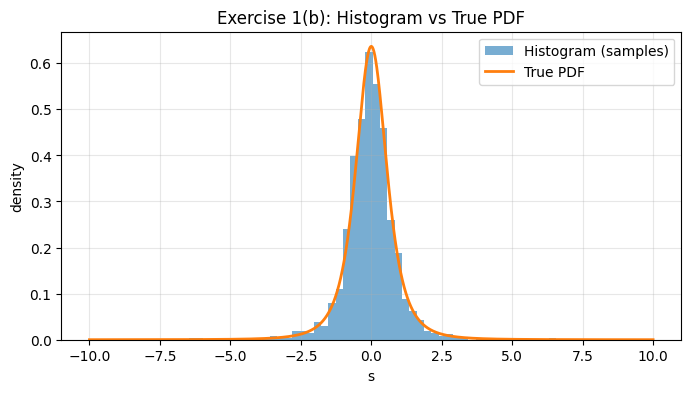

In [ ]:
xgrid = np.linspace(-10, 10, 2000)

plt.figure(figsize=(8,4))
plt.hist(S, bins=50, density=True, alpha=0.6, label="Histogram (samples)")
plt.plot(xgrid, pdf_true(xgrid), linewidth=2, label="True PDF")
plt.title("Exercise 1(b): Histogram vs True PDF")
plt.xlabel("s")
plt.ylabel("density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Qualitative comparison: empirical CDF vs true CDF

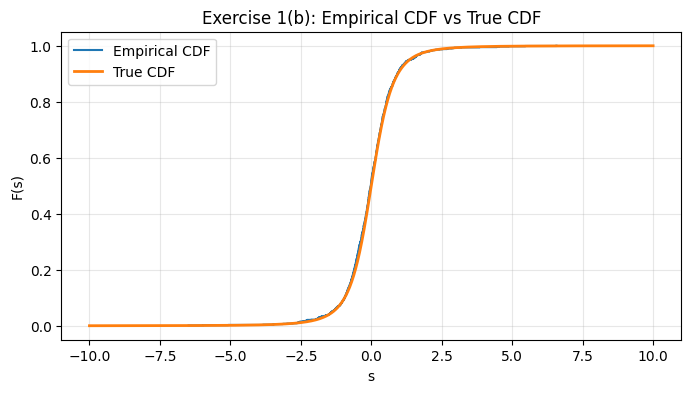

In [ ]:
S_sorted = np.sort(S)
ecdf = np.arange(1, N+1) / N

plt.figure(figsize=(8,4))
plt.step(S_sorted, ecdf, where="post", label="Empirical CDF")
plt.plot(xgrid, cdf_true(xgrid), linewidth=2, label="True CDF")
plt.title("Exercise 1(b): Empirical CDF vs True CDF")
plt.xlabel("s")
plt.ylabel("F(s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Quantitative comparison: Kolmogorov–Smirnov test

In [ ]:
ks_stat, p_value = kstest(S, cdf_true)
print("KS statistic:", ks_stat)
print("p-value:", p_value)


KS statistic: 0.028617826082356856
p-value: 0.3787929956042775


## Exercise 1(c) — Monte Carlo estimate of \(\kappa = \mathbb{E}[S^2]\) and a 95% CI

Let \(S\) be the random variable with pdf \(f_S(s)\) given in Exercise 1.
Using \(N=1000\) i.i.d. samples \(S_1,\dots,S_N\), we estimate the *average kinetic energy*

$$
\kappa \;:=\; \mathbb{E}[S^2].
$$

Define the transformed samples
$$
Y_i \;:=\; S_i^2, \qquad i=1,\dots,N,
$$
so that \(\kappa = \mathbb{E}[Y]\).

### Monte Carlo estimator
The Monte Carlo estimator of \(\kappa\) is the sample mean of \(Y_i\):

$$
\widehat{\kappa}_N \;=\; \frac{1}{N}\sum_{i=1}^{N} Y_i
\;=\; \frac{1}{N}\sum_{i=1}^{N} S_i^2.
$$

### 95% confidence interval (CLT)
Let
$$
\widehat{\sigma}^2_Y \;=\; \frac{1}{N-1}\sum_{i=1}^{N}\left(Y_i-\widehat{\kappa}_N\right)^2
$$
be the unbiased sample variance of \(Y\), and \(\widehat{\sigma}_Y=\sqrt{\widehat{\sigma}^2_Y}\).

An approximate 95% confidence interval for \(\kappa\) is

$$
\widehat{\kappa}_N \;\pm\; z_{0.975}\,\frac{\widehat{\sigma}_Y}{\sqrt{N}},
$$

where \(z_{0.975}\approx 1.96\) is the 97.5% quantile of the standard normal distribution.


In [ ]:
import numpy as np
from scipy.stats import norm

N = len(S)                 # should be 1000, this is the sample produced from the previous step through Cauchy distribution
Y = S**2                   # kinetic energy samples

kappa_hat = np.mean(Y)     #using Monte Carlo for kinetic function
sY = np.std(Y, ddof=1)     # sample std of Y
z = norm.ppf(0.975)        # 1.96...

half_width = z * sY / np.sqrt(N)
print(half_width)
CI = (kappa_hat - half_width, kappa_hat + half_width)

print("Monte Carlo for kappa_hat =", kappa_hat)
print("95% CI    =", CI)


0.1932622778198907
Monte Carlo for kappa_hat = 0.9451502233728309
95% CI    = (np.float64(0.7518879455529403), np.float64(1.1384125011927217))


Exercise 1(d) — Choice of the importance density

We want to estimate the quantity

$$
\kappa = \mathbb{E}_f[S^2]
= \int_{\mathbb{R}} s^2 f(s)\,ds,
\qquad
f(s)=\frac{2}{\pi(1+s^2)^2}.
$$

Using importance sampling, this expectation can be rewritten as

$$
\kappa
= \int_{\mathbb{R}} s^2 \frac{f(s)}{g(s)} g(s)\,ds
= \mathbb{E}_g\!\left[S^2\,w(S)\right],
\qquad
w(s)=\frac{f(s)}{g(s)}.
$$

### Choice of the proposal density

The proposal density \(g(s)\) must:

- have support equal to \(\mathbb{R}\),
- be easy to sample from,
- have tails at least as heavy as those of \(f(s)\),
- lead to bounded importance weights.

We choose the standard Cauchy density

$$
g(s)=\frac{1}{\pi(1+s^2)}.
$$

This choice is natural because both \(f(s)\) and \(g(s)\) are symmetric,
heavy-tailed distributions defined on \(\mathbb{R}\).

### Importance weights

With this choice of \(g(s)\), the weights become

$$
w(s)=\frac{f(s)}{g(s)}=\frac{2}{1+s^2}.
$$

Since

$$
0 < w(s) \le 2 \quad \text{for all } s\in\mathbb{R},
$$

the weights are uniformly bounded.  
This guarantees finite variance of the importance sampling estimator and improves numerical stability.


In [ ]:
import numpy as np
from scipy.stats import cauchy, norm

# target pdf f(s)
def f_pdf(s):
    return 2.0 / (np.pi * (1.0 + s**2)**2)

# proposal pdf g(s): standard Cauchy
def g_pdf(s):
    return 1.0 / (np.pi * (1.0 + s**2))

def importance_sampling_kappa(N=1000, seed=0):
    rng = np.random.default_rng(seed)

    # sample from proposal g
    y = cauchy.rvs(size=N, random_state=rng)

    # weights w = f/g  (here simplifies nicely)
    w = 2.0 / (1.0 + y**2)

    # IS samples for the integrand: Z = h(y)*w(y), with h(y)=y^2
    Z = (y**2) * w

    kappa_hat = Z.mean()
    sZ = Z.std(ddof=1)
    z = norm.ppf(0.975)  # 95% two-sided

    half_width = z * sZ / np.sqrt(N)
    CI = (kappa_hat - half_width, kappa_hat + half_width)
    print(half_width)
    return kappa_hat, CI


kappa_is, CI_is = importance_sampling_kappa(N=1000, seed=42)
print("IS kappa_hat =", kappa_is)
print("IS 95% CI    =", CI_is)


0.04381390963969173
IS kappa_hat = 1.0197017606623553
IS 95% CI    = (np.float64(0.9758878510226636), np.float64(1.063515670302047))


### Part (e) of exercise 1

In [ ]:
import numpy as np
from scipy.stats import norm

# ------------------------------------------------------------
# PDF target: f(s) = 2 / (pi * (1+s^2)^2)
# AR idea: propose Y ~ Cauchy(0,1), accept with prob 1/(1+Y^2)
# ------------------------------------------------------------
def sample_S_AR(N, seed=0):
    rng = np.random.default_rng(seed)
    out = np.empty(N)
    i = 0
    while i < N:
        u1 = rng.random()
        y  = np.tan(np.pi*(u1 - 0.5))      # Cauchy proposal
        u2 = rng.random()
        if u2 <= 1.0/(1.0 + y*y):          # accept
            out[i] = y
            i += 1
    return out

def ci95(x):
    x = np.asarray(x)
    n = len(x)
    m = x.mean()
    s = x.std(ddof=1)
    z = norm.ppf(0.975)  # ~1.96
    half = z * s / np.sqrt(n)
    return m, (m - half, m + half)

# =========================
# (1) Plain Monte Carlo
# =========================
N = 3000
S1 = sample_S_AR(N, seed=10)
S2 = sample_S_AR(N, seed=11)              # independent from S1

g_plain = np.minimum(S1, S2)              # g(s1,s2) = min(s1,s2)
mu_plain, CI_plain = ci95(g_plain)

print("PLAIN MC")
print("Estimate =", mu_plain)
print("95% CI   =", CI_plain)

# =========================
# (2) Antithetic variables
# Formulation:
#   mu_AV = (1/n) sum_i 0.5*( g(S1_i,S2_i) + g(-S1_i,-S2_i) )
# Use n = 1500 pairs -> total function evals = 3000 (fair)
# =========================
n_pairs = 1500

A1 = sample_S_AR(n_pairs, seed=20)        # base samples for electron 1
A2 = sample_S_AR(n_pairs, seed=21)        # base samples for electron 2 (independent)

g      = np.minimum(A1, A2)
g_ant  = np.minimum(-A1, -A2)
Z_av   = 0.5*(g + g_ant)                  # one "paired" sample per i

mu_av, CI_av = ci95(Z_av)

print("\nANTITHETIC")
print("Estimate =", mu_av)
print("95% CI   =", CI_av)

half_plain = (CI_plain[1] - CI_plain[0]) / 2
half_av    = (CI_av[1]    - CI_av[0])    / 2
print("\nCI half-width: plain vs antithetic =", half_plain, "vs", half_av)


PLAIN MC
Estimate = -0.4931505860670359
95% CI   = (np.float64(-0.5241026346923386), np.float64(-0.4621985374417331))

ANTITHETIC
Estimate = -0.47117135363540774
95% CI   = (np.float64(-0.4945156941923853), np.float64(-0.4478270130784302))

CI half-width: plain vs antithetic = 0.030952048625302764 vs 0.02334434055697754
